In [1]:
import pandas as pd 
import seaborn as sns

In [3]:
1889.5/56.95

33.17822651448639

In [2]:
df  =  pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.drop(df[df["TotalCharges"] ==" "].index  , axis = 0 , inplace = True)

In [6]:
df["TotalCharges"]= df["TotalCharges"].astype(float)

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
h_missing = [" " , "?" , "unknown" , "missing"]

for col in df.select_dtypes("str").columns:
    for fake in h_missing : 
        count  = (df[col] == fake).sum()
        if count > 0 :
            print(f"col {col}  has fake  {fake}")

In [10]:
cat  =  df.select_dtypes("str").columns.tolist()

cat.remove("customerID")
cat

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

In [11]:
df["gender"].unique()

<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

In [12]:
# cat  =  df.select_dtypes("str").columns.tolist()
# cat = cat.remove("customerID")

for col in cat :
    print("="*20  , col  , "="*20)
    print(df[col].unique())

==================== gender ====================
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
==================== Partner ====================
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
==================== Dependents ====================
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
==================== PhoneService ====================
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
==================== MultipleLines ====================
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
==================== InternetService ====================
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
==================== OnlineSecurity ====================
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
==================== OnlineBackup ====================
<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
==================== DeviceProtection ===

In [13]:
# target distribtion
print("="*20 , "Target values")
print(df["Churn"].value_counts())

print("="*20 , "Target pecentage")
print(df["Churn"].value_counts(normalize = True))

==================== Target values
Churn
No     5163
Yes    1869
Name: count, dtype: int64
==================== Target pecentage
Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64


#EDA

<Axes: xlabel='Churn', ylabel='probability'>

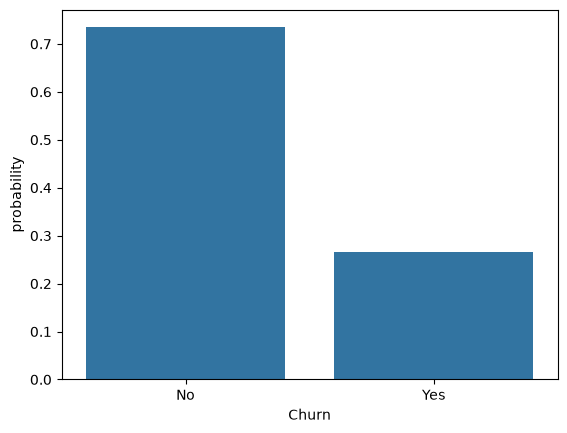

In [14]:
sns.countplot(df , x = "Churn" , stat = "probability")

<Axes: xlabel='tenure', ylabel='Count'>

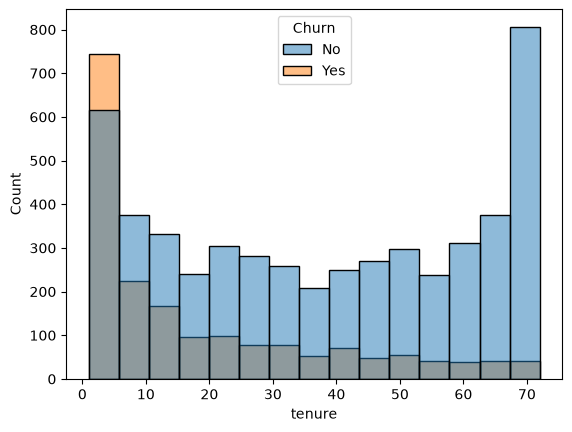

In [ ]:
sns.histplot(df , x = "tenure"  ,hue = "Churn")

In [ ]:
df_eda = df.copy()
df["TenureGroup"] =  pd.cut(df_eda["tenure"],  bins = [-1 , 12 , 24 , 48 , 60 , 75] , labels = ["1_year" ,"2_year" ,"4_year" , "5_years" ,"+5_years"])
df_eda

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,1_year
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,4_year
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1_year
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,4_year
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1_year
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,2_year
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,+5_years
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,1_year
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,1_year


In [ ]:
df_eda

In [ ]:
ten_ch =  df_eda.groupby("TenureGroup").agg(Customers = ("Churn" , "size") , Churn_rate =  ("Churn" , lambda x : x.eq("Yes").mean()*100))
ten_ch

,Customers,Churn_rate
TenureGroup,,
1_year,2175,47.678161
2_year,1024,28.710938
4_year,1594,20.388959
5_years,832,14.423077
+5_years,1407,6.609808


In [44]:
contract_summary =  df_eda.groupby("Contract").agg(churned_customers = ("Churn" , lambda x : x.eq("Yes").sum()) , Churn_rate =  ("Churn" , lambda x : x.eq("Yes").mean()*100))
contract_summary

,churned_customers,Churn_rate
Contract,,
Month-to-month,1655,42.709677
One year,166,11.277174
Two year,48,2.848665


In [45]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,1_year
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,4_year
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1_year
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,4_year
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1_year
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,2_year
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,+5_years
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,1_year
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,1_year


In [15]:
x =  df.drop(["customerID" , 'Churn'] , axis = 1)
y = df.Churn

In [16]:
y =y.map({"Yes" :1 , "No" :0})

In [17]:
cat  = x.select_dtypes("str").columns.tolist()
num  = x.select_dtypes("number").columns.tolist()

In [123]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test  =  train_test_split(x ,y ,test_size=0.2    , random_state=42 , stratify=y)

x_test.shape  , x_train.shape

((1407, 19), (5625, 19))

In [124]:
#SMOTE

In [125]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler  , SMOTE

x_train  =  prepro.fit_transform(x_train)
x_test = prepro.transform(x_test)
# sampler  = RandomUnderSampler()
# sampler  = RandomOverSampler()
sampler  = SMOTE()

x_train_res   , y_train_res =  sampler.fit_resample(x_train , y_train)

In [126]:
 x_train_res.shape

(8260, 19)

In [127]:
y_train.value_counts()

Churn
0    4130
1    1495
Name: count, dtype: int64

In [128]:
4130-1495

2635

In [129]:
# x_train.duplicated().sum()
x_train_res.duplicated().sum()

AttributeError: 'numpy.ndarray' object has no attribute 'duplicated'

In [119]:
y_train_res.value_counts()

Churn
0    4130
1    4130
Name: count, dtype: int64

In [83]:
from sklearn.preprocessing import OrdinalEncoder

In [106]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder , StandardScaler

num_tras =  Pipeline(steps = [
    ("imoputer" , SimpleImputer(strategy="median")) 
])

cat_tras =  Pipeline(steps = [
    ("imputer" , SimpleImputer(strategy="most_frequent")) , ("ohe" , OrdinalEncoder(handle_unknown="use_encoded_value" , unknown_value=np.nan))
])


prepro = ColumnTransformer(transformers = [
    ("num" , num_tras , num),
    ("cat" , cat_tras , cat)
])

In [145]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier  
from sklearn.metrics import accuracy_score , confusion_matrix

In [90]:
x_train

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
1413,Male,0,Yes,Yes,65,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,No,No,Two year,No,Credit card (automatic),94.55,6078.75
7003,Male,0,No,No,26,No,No phone service,DSL,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,35.75,1022.50
3355,Female,0,Yes,No,68,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,No,No,Two year,No,Credit card (automatic),90.20,6297.65
4494,Male,0,No,No,3,Yes,No,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,No,Electronic check,84.30,235.05
3541,Female,0,Yes,No,49,No,No phone service,DSL,Yes,No,No,No,Yes,No,Month-to-month,No,Bank transfer (automatic),40.65,2070.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3451,Male,1,Yes,No,65,Yes,No,Fiber optic,No,No,No,No,No,No,One year,Yes,Bank transfer (automatic),70.95,4555.20
5123,Female,1,No,No,15,Yes,No,Fiber optic,No,Yes,No,No,No,No,Month-to-month,Yes,Credit card (automatic),75.30,1147.45
4135,Female,0,Yes,Yes,36,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),92.90,3379.25
4249,Female,0,Yes,Yes,10,Yes,No,DSL,No,Yes,Yes,No,No,Yes,One year,Yes,Mailed check,65.90,660.05


In [146]:
# dt  =  DecisionTreeClassifier(random_state=42  , max_depth= 8 , min_samples_leaf=4 , min_samples_split=2 , criterion="gini" )
# dt2  =  DecisionTreeClassifier(random_state=42  , max_depth= 8 , min_samples_leaf=4 , min_samples_split=2 , criterion="gini" )
rf  =  RandomForestClassifier( max_depth= 8 , min_samples_leaf=4 , min_samples_split=2 , criterion="gini")
model  =  Pipeline(steps=[ ("dt" , rf)])
# model  =  Pipeline(steps=[("preprocessor" ,prepro ) , ("dt" , dt)])

model.fit(x_train_res ,y_train_res)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dt', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'


In [140]:
3*4*4*4

192

In [152]:
cret = ["log_loss" , "gini" ]
max_depths = [None , 4 , 8 , 12]
min_samples = [2 , 20  , 50]
min_samples_leaf = [1 , 2  ,10]
accs = []
n_est =  [100,200,300]
for c in cret :
    for depth in max_depths :
        for min_s in min_samples :
            for leaf in min_samples_leaf:
             for n in n_est:

            #    dt  =  DecisionTreeClassifier(criterion=c , min_samples_split=min_s , min_samples_leaf= leaf , max_depth=depth,random_state=42 )
            #    dt  =  DecisionTreeClassifier(criterion=c , min_samples_split=min_s , min_samples_leaf= leaf , max_depth=depth,random_state=42 )
               dt  =  RandomForestClassifier( n_estimators=n , criterion=c , min_samples_split=min_s , min_samples_leaf= leaf , max_depth=depth,random_state=42 )
               model  =  Pipeline(steps=[ ("rf" , rf )])
                
               model.fit(x_train_res ,y_train_res)
               acc =  accuracy_score(y_test  , model.predict(x_test))
               accs.append((depth , leaf , min_s , c , acc))
               print(f"depth  {depth}  , min_s {min_s} , leaf {leaf} , c {c}   n_est {n} acc is {acc}")

depth  None  , min_s 2 , leaf 1 , c log_loss   n_est 100 acc is 0.767590618336887
depth  None  , min_s 2 , leaf 1 , c log_loss   n_est 200 acc is 0.7647476901208244
depth  None  , min_s 2 , leaf 1 , c log_loss   n_est 300 acc is 0.7654584221748401
depth  None  , min_s 2 , leaf 2 , c log_loss   n_est 100 acc is 0.7697228144989339
depth  None  , min_s 2 , leaf 2 , c log_loss   n_est 200 acc is 0.7718550106609808
depth  None  , min_s 2 , leaf 2 , c log_loss   n_est 300 acc is 0.7711442786069652
depth  None  , min_s 2 , leaf 10 , c log_loss   n_est 100 acc is 0.7640369580668088
depth  None  , min_s 2 , leaf 10 , c log_loss   n_est 200 acc is 0.7697228144989339
depth  None  , min_s 2 , leaf 10 , c log_loss   n_est 300 acc is 0.7711442786069652
depth  None  , min_s 20 , leaf 1 , c log_loss   n_est 100 acc is 0.7711442786069652
depth  None  , min_s 20 , leaf 1 , c log_loss   n_est 200 acc is 0.7640369580668088
depth  None  , min_s 20 , leaf 1 , c log_loss   n_est 300 acc is 0.7654584221748401

In [154]:
sorted(accs , key =lambda x : x[4]  , reverse=True )

[(8, 10, 20, 'gini', 0.7775408670931059),
 (12, 2, 2, 'gini', 0.7768301350390903),
 (None, 10, 20, 'log_loss', 0.7761194029850746),
 (4, 10, 2, 'log_loss', 0.7761194029850746),
 (12, 2, 20, 'log_loss', 0.775408670931059),
 (12, 10, 20, 'gini', 0.7746979388770433),
 (12, 2, 2, 'log_loss', 0.7739872068230277),
 (None, 2, 2, 'gini', 0.7739872068230277),
 (4, 1, 50, 'gini', 0.7739872068230277),
 (4, 10, 50, 'gini', 0.7739872068230277),
 (8, 10, 20, 'gini', 0.7739872068230277),
 (8, 1, 20, 'log_loss', 0.7732764747690121),
 (12, 1, 20, 'log_loss', 0.7732764747690121),
 (12, 2, 50, 'log_loss', 0.7732764747690121),
 (4, 10, 50, 'gini', 0.7732764747690121),
 (8, 2, 2, 'gini', 0.7732764747690121),
 (None, 2, 20, 'log_loss', 0.7725657427149965),
 (None, 10, 50, 'log_loss', 0.7725657427149965),
 (4, 2, 2, 'log_loss', 0.7725657427149965),
 (4, 1, 20, 'log_loss', 0.7725657427149965),
 (12, 1, 2, 'log_loss', 0.7725657427149965),
 (12, 10, 2, 'log_loss', 0.7725657427149965),
 (None, 1, 2, 'gini', 0.77

In [155]:
from sklearn.metrics import accuracy_score , confusion_matrix

accuracy_score(y_train  , model.predict(x_train))  , accuracy_score(y_test  , model.predict(x_test))

(0.8216888888888889, 0.7690120824449183)

In [156]:
from sklearn.metrics import precision_score , recall_score

precision_score(y_test  , model.predict(x_test))

0.5543237250554324

In [157]:
recall_score(y_test  , model.predict(x_test))


0.6684491978609626

In [112]:
748/(748+285)

0.7241045498547919

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='predicted label', ylabel='true label'>)

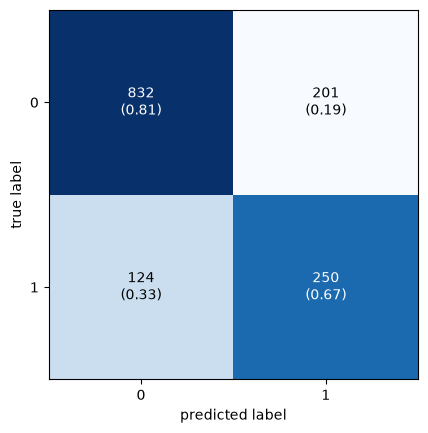

In [159]:
from mlxtend.plotting import plot_confusion_matrix
cm   = confusion_matrix(y_test  , model.predict(x_test))

plot_confusion_matrix(cm , show_normed=True)

In [ ]:
# import joblib
# joblib.dump(model,"customer_churn.pkl")

['customer_churn.pkl']

In [51]:
import numpy as np 
np.bincount(y_test)

array([1033,  374])

In [54]:
1000/(2*1033)

0.484027105517909

In [49]:
y_test.value_counts()

Churn
0    1033
1     374
Name: count, dtype: int64

# Decision tree 

In [ ]:
from 

In [20]:
df  = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [19]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [20]:
df.dropna(subset = "embark_town" , inplace = True)
df.drop("deck" , axis = 1 , inplace =True)
df["age"] = df["age"].fillna(df["age"].mean())

In [21]:
x =  df.drop(["survived" , "alive"] , axis = 1)
y = df.survived

In [22]:
cat  =  x.select_dtypes(["str" , "category"]).columns.tolist()


In [23]:
from sklearn.preprocessing import LabelEncoder
for col in cat :
 encoder = LabelEncoder()
 x[col] = encoder.fit_transform(x[col])

In [24]:
x

,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alone
0,3,1,22.000000,1,0,7.2500,2,2,1,True,2,False
1,1,0,38.000000,1,0,71.2833,0,0,2,False,0,False
2,3,0,26.000000,0,0,7.9250,2,2,2,False,2,True
3,1,0,35.000000,1,0,53.1000,2,0,2,False,2,False
4,3,1,35.000000,0,0,8.0500,2,2,1,True,2,True
...,...,...,...,...,...,...,...,...,...,...,...,...
886,2,1,27.000000,0,0,13.0000,2,1,1,True,2,True
887,1,0,19.000000,0,0,30.0000,2,0,2,False,2,True
888,3,0,29.642093,1,2,23.4500,2,2,2,False,2,False
889,1,1,26.000000,0,0,30.0000,0,0,1,True,0,True


In [31]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test  =  train_test_split(x ,y ,test_size=0.2    , random_state=42 , stratify=y)

x_test.shape  , x_train.shape

((178, 12), (711, 12))

In [28]:
import matplotlib.pyplot as plt 

In [73]:
from sklearn.tree import DecisionTreeClassifier , plot_tree
model = DecisionTreeClassifier(criterion="log_loss",max_depth=8, min_samples_split=10, random_state=42  ,min_samples_leaf=5)
model.fit(x_train , y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'log_loss'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [69]:
model.max_d

AttributeError: 'DecisionTreeClassifier' object has no attribute 'max_d'

In [74]:
from sklearn.metrics import accuracy_score
accuracy_score(y_train , model.predict(x_train)) , accuracy_score(y_test , model.predict(x_test))

(0.8734177215189873, 0.8314606741573034)

In [64]:
from sklearn.metrics import accuracy_score
accuracy_score(y_train , model.predict(x_train)) , accuracy_score(y_test , model.predict(x_test))

(0.8284106891701828, 0.8146067415730337)

[Text(0.5, 0.9166666666666666, 'adult_male <= 0.5\ngini = 0.472\nsamples = 711\nvalue = [439, 272]\nclass = not survived'),
 Text(0.25, 0.75, 'class <= 1.5\ngini = 0.404\nsamples = 285\nvalue = [80, 205]\nclass = survived'),
 Text(0.375, 0.8333333333333333, 'True  '),
 Text(0.125, 0.5833333333333334, 'fare <= 28.856\ngini = 0.092\nsamples = 144\nvalue = [7, 137]\nclass = survived'),
 Text(0.0625, 0.4166666666666667, 'gini = 0.185\nsamples = 58\nvalue = [6, 52]\nclass = survived'),
 Text(0.1875, 0.4166666666666667, 'gini = 0.023\nsamples = 86\nvalue = [1, 85]\nclass = survived'),
 Text(0.375, 0.5833333333333334, 'fare <= 17.6\ngini = 0.499\nsamples = 141\nvalue = [73, 68]\nclass = not survived'),
 Text(0.3125, 0.4166666666666667, 'gini = 0.475\nsamples = 90\nvalue = [35.0, 55.0]\nclass = survived'),
 Text(0.4375, 0.4166666666666667, 'gini = 0.38\nsamples = 51\nvalue = [38, 13]\nclass = not survived'),
 Text(0.75, 0.75, 'fare <= 26.269\ngini = 0.265\nsamples = 426\nvalue = [359, 67]\ncla

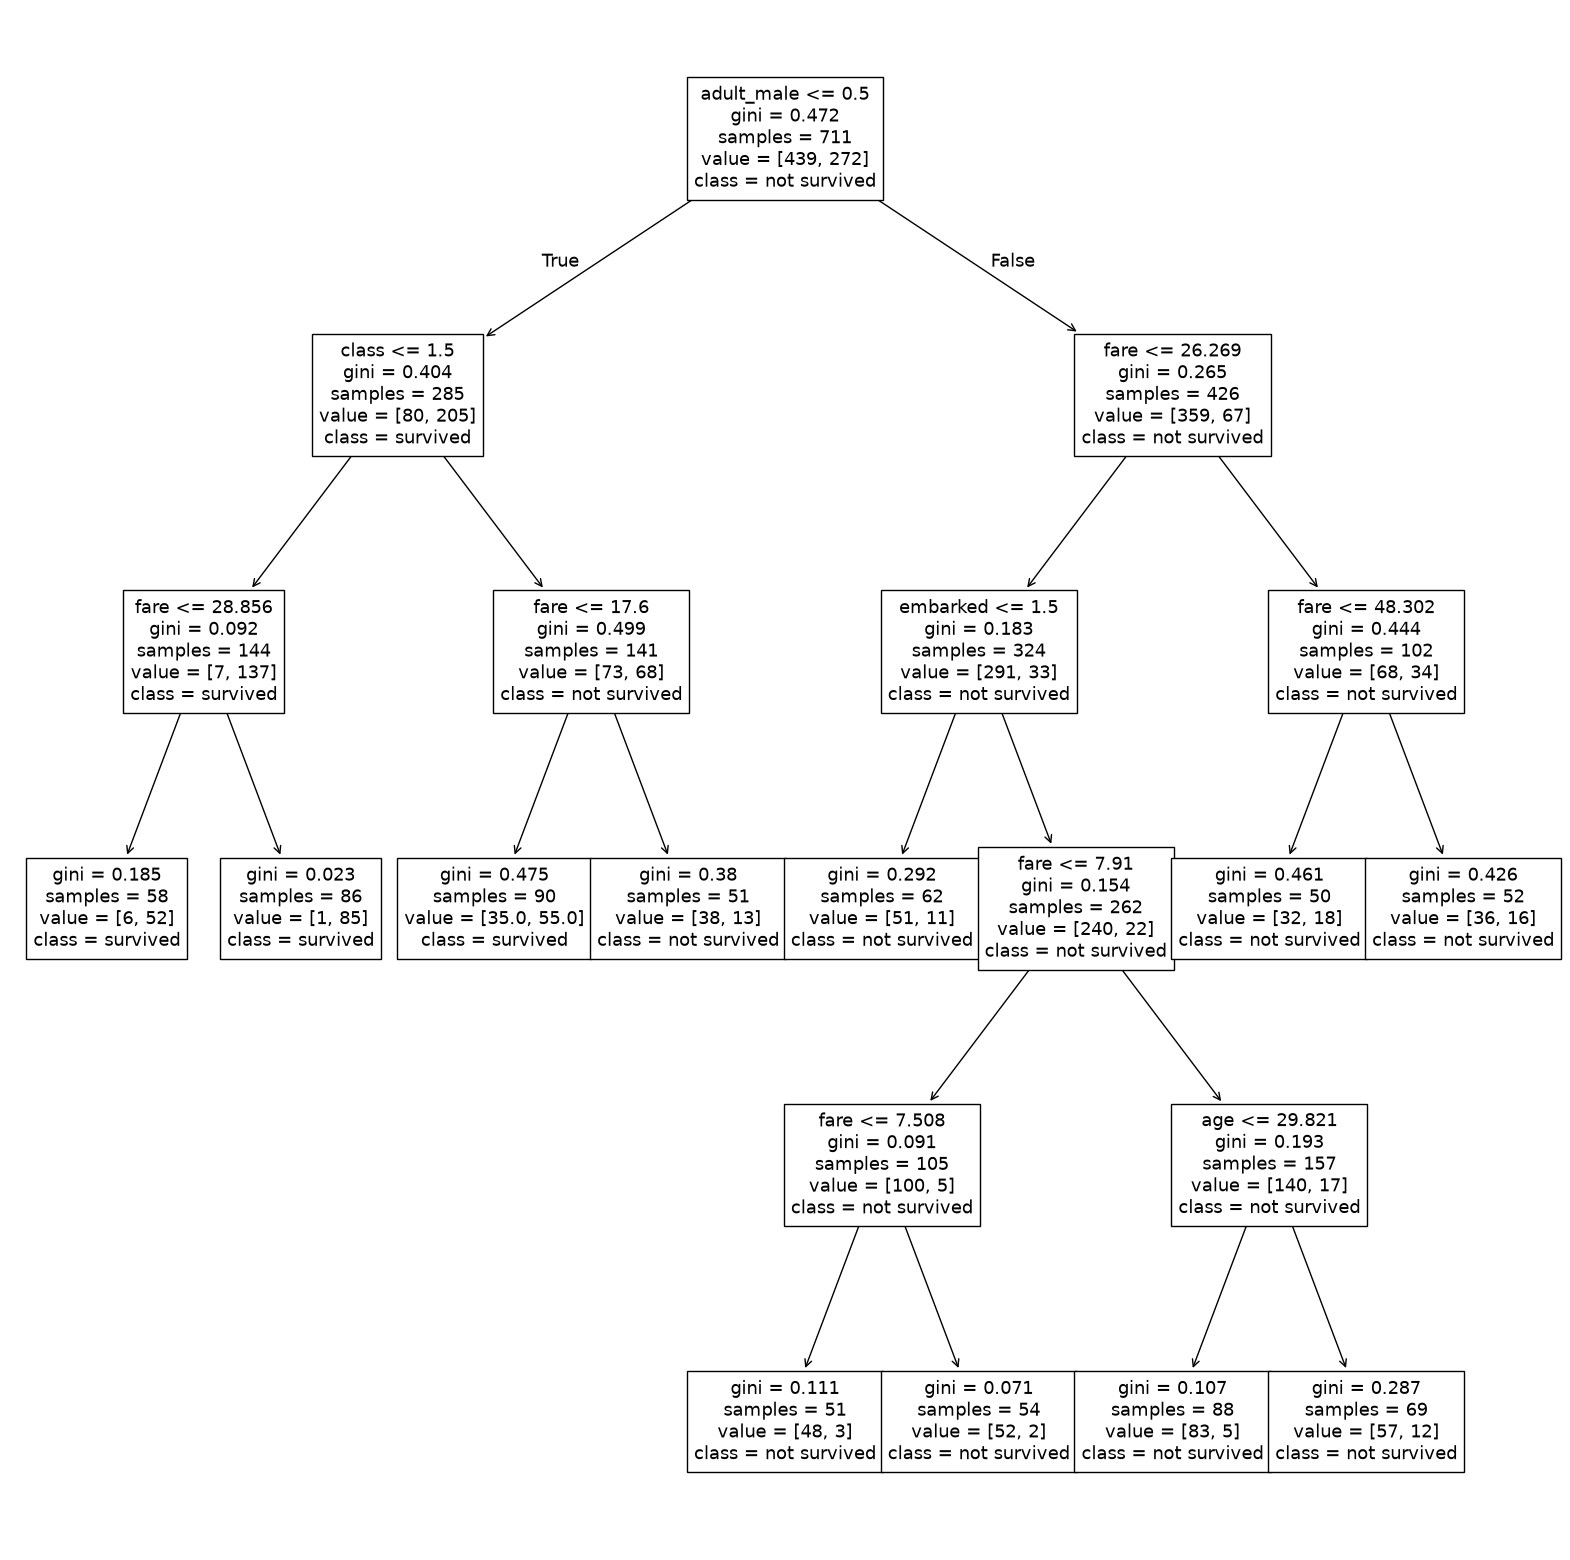

In [65]:
plt.figure(figsize=(20, 20))
plot_tree(model , feature_names=x.columns , class_names = ["not survived"  , "survived"] )

In [29]:
x

,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alone
0,3,1,22.000000,1,0,7.2500,2,2,1,True,2,False
1,1,0,38.000000,1,0,71.2833,0,0,2,False,0,False
2,3,0,26.000000,0,0,7.9250,2,2,2,False,2,True
3,1,0,35.000000,1,0,53.1000,2,0,2,False,2,False
4,3,1,35.000000,0,0,8.0500,2,2,1,True,2,True
...,...,...,...,...,...,...,...,...,...,...,...,...
886,2,1,27.000000,0,0,13.0000,2,1,1,True,2,True
887,1,0,19.000000,0,0,30.0000,2,0,2,False,2,True
888,3,0,29.642093,1,2,23.4500,2,2,2,False,2,False
889,1,1,26.000000,0,0,30.0000,0,0,1,True,0,True
